# Sleep Patterns and Screen Time Analysis Using Python

**Assignment 12 — Data Analysis & Visualization**

> Dataset note: This is simulated teaching data, not a real student survey.

## Before running
1. In Google Colab, open the **Files** panel on the left.
2. Upload `sleep_screen_time_data.csv` from the same folder as this notebook.
3. Confirm the CSV appears in the Files panel, then run the code cell below.
4. If the file is missing, the code now stops with a clear error instead of waiting for an upload dialog.

This notebook uses Pandas, NumPy, Matplotlib, and Seaborn. These are commonly preinstalled in Google Colab; no `pip install` cell is needed.


In [2]:
from google.colab import files
uploaded = files.upload()

KeyboardInterrupt: 

Loading dataset from: /content/sleep_screen_time_data.csv

RAW DATA PREVIEW


,Student_ID,Study_Hours,Screen_Time_Hours,Sleep_Hours,Concentration_Score,Physical_Activity_Minutes
0,S001,1,6.2,7.1,100.0,17
1,S002,7,5.1,6.8,71.9,72
2,S003,6,5.5,6.3,74.3,52
3,S004,4,6.1,5.3,72.6,60
4,S005,4,2.5,6.4,95.2,35


Original shape (rows, columns): (101, 6)

Missing values before cleaning:
Student_ID                   0
Study_Hours                  0
Screen_Time_Hours            0
Sleep_Hours                  3
Concentration_Score          2
Physical_Activity_Minutes    0
dtype: int64

Duplicate rows before cleaning: 1

Cleaned shape (rows, columns): (100, 6)
Missing values after cleaning:
Student_ID                   0
Study_Hours                  0
Screen_Time_Hours            0
Sleep_Hours                  0
Concentration_Score          0
Physical_Activity_Minutes    0
dtype: int64

NUMERICAL SUMMARY
Average sleep: 6.75 hours
Minimum sleep: 4.00 hours
Maximum sleep: 9.40 hours
Sleep standard deviation: 1.06 hours
Average screen time: 4.79 hours/day
Average concentration score: 81.17/100
Total physical activity: 4427 minutes

CORRELATION MATRIX


,Study_Hours,Screen_Time_Hours,Sleep_Hours,Concentration_Score,Physical_Activity_Minutes
Study_Hours,1.00,-0.02,-0.11,-0.22,-0.07
Screen_Time_Hours,-0.02,1.00,-0.52,-0.56,-0.09
Sleep_Hours,-0.11,-0.52,1.00,0.59,0.05
Concentration_Score,-0.22,-0.56,0.59,1.00,-0.03
Physical_Activity_Minutes,-0.07,-0.09,0.05,-0.03,1.00


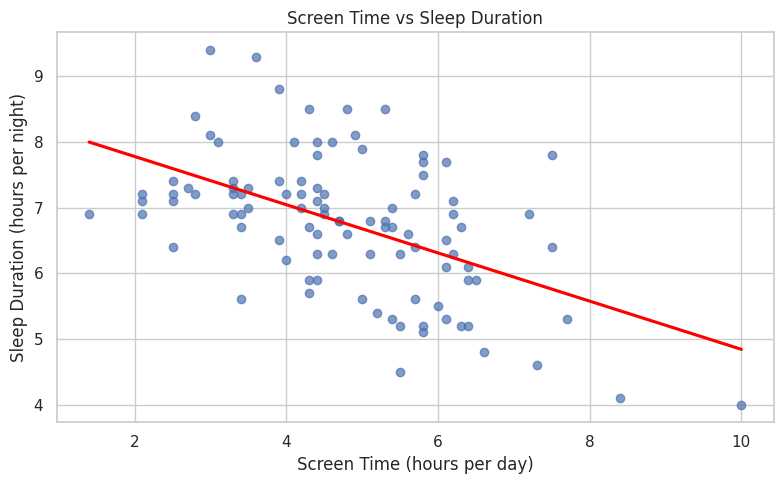

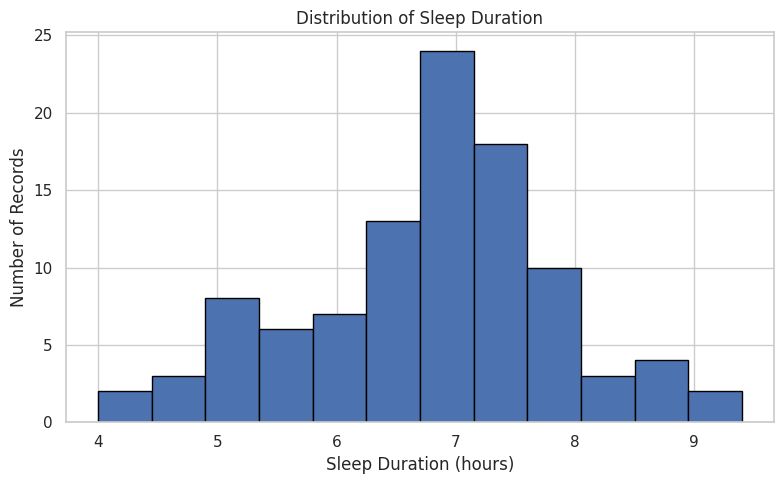

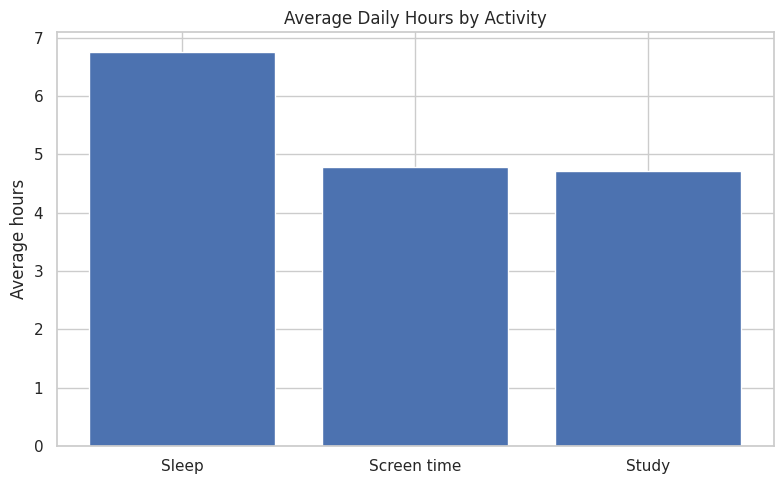

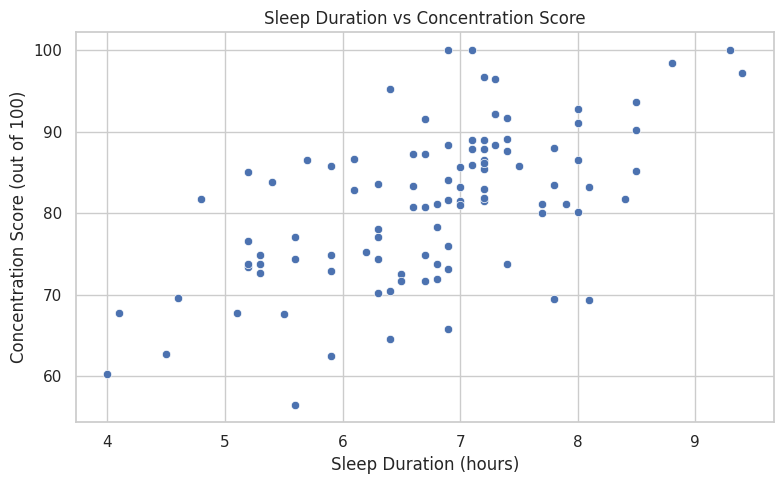

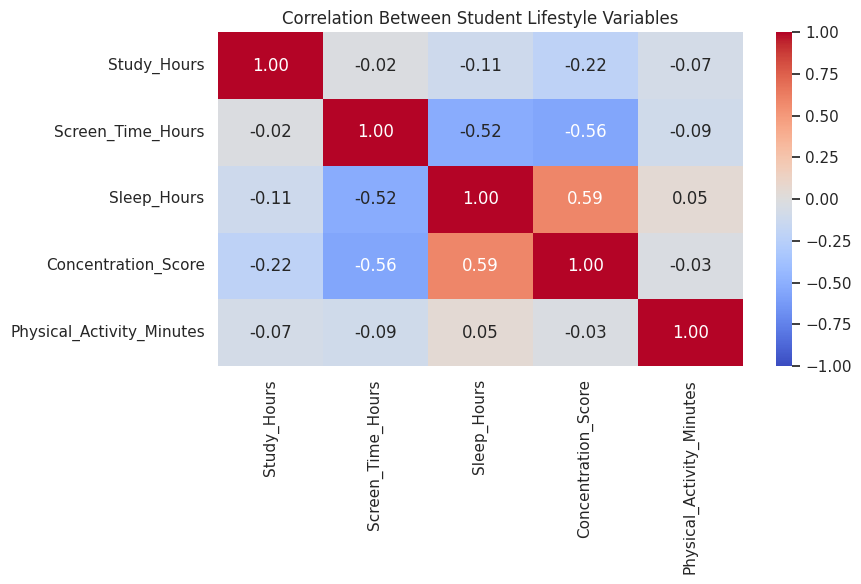


Project complete! Five graphs were displayed in 0.8 seconds.
Reminder: These are simulated teaching data, not a real student survey.


In [3]:
# SLEEP PATTERNS AND SCREEN TIME ANALYSIS USING PYTHON
# Simulated teaching data for demonstration; NOT a real student survey.

from pathlib import Path
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

start_time = time.time()

# 1. Load the dataset. In Colab, upload sleep_screen_time_data.csv via the Files panel first.
candidates = [Path('/content/sleep_screen_time_data.csv'), Path.cwd() / 'sleep_screen_time_data.csv']
# For a local .py run, also look beside this script.
try:
    candidates.append(Path(__file__).resolve().parent / 'sleep_screen_time_data.csv')
except NameError:
    pass
file_path = next((p for p in candidates if p.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        'Cannot find sleep_screen_time_data.csv. In Google Colab, open the Files panel '
        'on the left and upload that CSV, then rerun this cell. For local Python, keep the '
        'CSV in the same folder as this script/notebook.'
    )

print(f'Loading dataset from: {file_path}')
df = pd.read_csv(file_path)
print('\nRAW DATA PREVIEW')
display(df.head())
print('Original shape (rows, columns):', df.shape)

# 2. Inspect and clean the data
print('\nMissing values before cleaning:')
print(df.isnull().sum())
print('\nDuplicate rows before cleaning:', df.duplicated().sum())

df = df.drop_duplicates().copy()

numeric_cols = [
    'Study_Hours',
    'Screen_Time_Hours',
    'Sleep_Hours',
    'Concentration_Score',
    'Physical_Activity_Minutes',
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].median())

print('\nCleaned shape (rows, columns):', df.shape)
print('Missing values after cleaning:')
print(df.isnull().sum())

# 3. Numerical analysis using NumPy
sleep = df['Sleep_Hours'].to_numpy(dtype=float)
screen = df['Screen_Time_Hours'].to_numpy(dtype=float)
focus = df['Concentration_Score'].to_numpy(dtype=float)

print('\nNUMERICAL SUMMARY')
print(f'Average sleep: {np.mean(sleep):.2f} hours')
print(f'Minimum sleep: {np.min(sleep):.2f} hours')
print(f'Maximum sleep: {np.max(sleep):.2f} hours')
print(f'Sleep standard deviation: {np.std(sleep):.2f} hours')
print(f'Average screen time: {np.mean(screen):.2f} hours/day')
print(f'Average concentration score: {np.mean(focus):.2f}/100')
print(f'Total physical activity: {np.sum(df["Physical_Activity_Minutes"].to_numpy(dtype=float)):.0f} minutes')

correlation = df[numeric_cols].corr(numeric_only=True)
print('\nCORRELATION MATRIX')
display(correlation.round(2))

# 4. Visualizations. Each figure is closed after display to keep memory usage low.
sns.set_theme(style='whitegrid')

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='Screen_Time_Hours', y='Sleep_Hours',
            scatter_kws={'alpha': 0.7}, line_kws={'color': 'red'}, ci=None)
plt.title('Screen Time vs Sleep Duration')
plt.xlabel('Screen Time (hours per day)')
plt.ylabel('Sleep Duration (hours per night)')
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
plt.hist(df['Sleep_Hours'], bins=12, edgecolor='black')
plt.title('Distribution of Sleep Duration')
plt.xlabel('Sleep Duration (hours)')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
means = [df['Sleep_Hours'].mean(), df['Screen_Time_Hours'].mean(), df['Study_Hours'].mean()]
plt.bar(['Sleep', 'Screen time', 'Study'], means)
plt.title('Average Daily Hours by Activity')
plt.ylabel('Average hours')
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sleep_Hours', y='Concentration_Score')
plt.title('Sleep Duration vs Concentration Score')
plt.xlabel('Sleep Duration (hours)')
plt.ylabel('Concentration Score (out of 100)')
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Between Student Lifestyle Variables')
plt.tight_layout()
plt.show()
plt.close()

print(f'\nProject complete! Five graphs were displayed in {time.time() - start_time:.1f} seconds.')
print('Reminder: These are simulated teaching data, not a real student survey.')
